In [46]:

import numpy as np
import pandas as pd

from xgboost import XGBRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor


from sklearn.metrics import  mean_absolute_percentage_error # MAPE

from sklearn.model_selection import train_test_split

import math

import glob
import time

import os

import matplotlib.pyplot as plt

#### **Load the Data**

In [ ]:
# ============================================================
# 2) LOAD PREPROCESSED DATA
# ============================================================

path = os.getenv("DIR_PATH")

files = glob.glob(f"{path}/results/*.csv")

print("Number of files:", len(files))

dfs = []
for index , path in enumerate(files):
    print(index , end=" " , flush=True)
    df = pd.read_csv(path)
    dfs.append(df)
print()

df = pd.concat(dfs)

print("[+] Shape:", df.shape)

Number of files: 48
0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 
[+] Shape: (1309053, 172)


In [20]:
del dfs

#### **Log Scaling**

In [ ]:
n = len(df.columns.drop(["dayofweek" , "month" , "hour" ]))
counter = 0
for feature_name in df.columns.drop(["dayofweek" , "month" , "hour" ]) :
    df[feature_name] = df[feature_name].apply(lambda x : math.log(x))
    counter +=1
    if counter%10 == 0 :
        print(f"{n}/{counter}")
print(f"[+] Finish : {n}/{counter}")

In [22]:
# --------------------------------
# 4. Define features and target
# --------------------------------
lag_features = [f"t-{lag}" for lag in range(1, 169)]

time_features = [ "hour", "dayofweek", "month" ]

target = "target"

feature_cols = lag_features + time_features

X = df[feature_cols]
y = df[target]

In [24]:
del df

#### **Train-Test Split**

In [25]:


X_train, X_test, y_train, y_test = train_test_split(X , y , train_size=0.8 , shuffle=True , random_state=42)



In [26]:
del X,y

<hr color=white>

# **LinearRegression**

In [ ]:
Linear_Regression_model = LinearRegression()
print(f"[+] Training the model ...")
t1 = time.time()
Linear_Regression_model.fit(X_train , y_train)
t2 = time.time()
diff = t2-t1
minute = f"{diff//60 :.0f}".zfill(2)
second = f"{diff% 60 :.0f}".zfill(2)
print(f"[+] Training Completed Successfully, Took {minute}:{second}")

y_pred = Linear_Regression_model.predict(X_train)
linear_regression_train_mape = mean_absolute_percentage_error(y_train , y_pred)
print("MAPE Train :", linear_regression_train_mape)
y_pred = Linear_Regression_model.predict(X_test)
linear_regression_test_mape = mean_absolute_percentage_error(y_test , y_pred)
print("MAPE Test :", linear_regression_test_mape)

print("Train Accurcy : " , (1 - linear_regression_train_mape) * 100)
print("Test Accurcy  : " , (1 - linear_regression_test_mape) * 100)


[+] Testing the model ...
[+] Training Completed Successfully, Took 00:15
MAPE Train : 0.03663779248861876
MAPE Test : 0.03521618436955789
Train Accurcy :  96.33622075113813
Test Accurcy  :  96.47838156304421


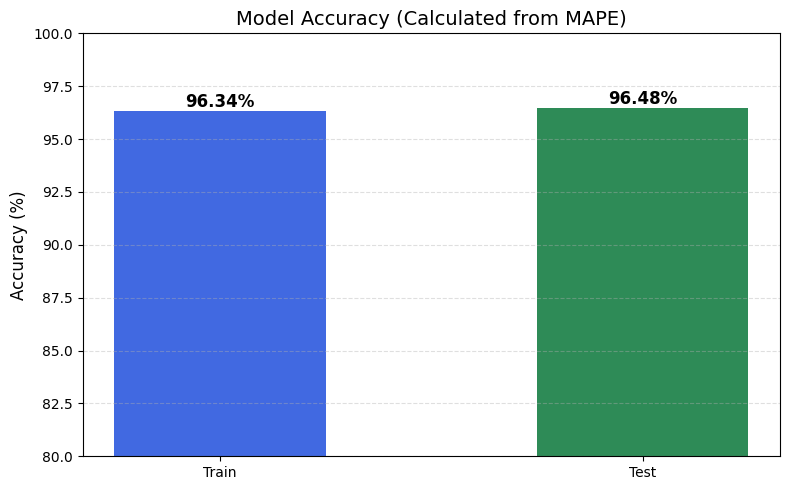

In [ ]:
labels = ['Train', 'Test']
accuracy = [(1 - linear_regression_train_mape) * 100  , (1 - linear_regression_test_mape) * 100  ]
plt.figure(figsize=(8, 5))
bars = plt.bar( labels, accuracy, color=['royalblue', 'seagreen'], width=0.5 )
for bar in bars:
    height = bar.get_height()
    plt.text( bar.get_x() + bar.get_width()/2, height + 0.2, f'{height:.2f}%', ha='center', fontsize=12, fontweight='bold' )

plt.title('Model Accuracy (Calculated from MAPE)', fontsize=14)
plt.ylabel('Accuracy (%)', fontsize=12)
plt.ylim(80, 100)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

<hr color=white>

# **RandomForestRegressor**

In [32]:
train_mape_results = []
test_mape_results = []

train_accu_results = []
test_accu_results = []

max_depth = [4 , 6 , 8 , 10 , 12]

for i in max_depth:
    Random_Forest_model = RandomForestRegressor(
        n_estimators=20,
        max_depth=i,
        random_state=42,
        n_jobs=-1,
    )
    print(f"[+] Training the model [max_depth={i}] ...")
    t1 = time.time()
    Random_Forest_model.fit(X_train , y_train)
    t2 = time.time()
    diff = t2-t1
    minute = f"{diff//60 :.0f}".zfill(2)
    second = f"{diff% 60 :.0f}".zfill(2)
    print(f"[+] Training Completed Successfully, Took {minute}:{second}")


    y_pred = Random_Forest_model.predict(X_train)
    random_forest_train_mape = mean_absolute_percentage_error(y_train , y_pred)
    train_mape_results.append(random_forest_train_mape)
    
    y_pred = Random_Forest_model.predict(X_test)
    random_forest_test_mape = mean_absolute_percentage_error(y_test , y_pred)
    test_mape_results.append(random_forest_test_mape)

    train_accu_results.append((1 - random_forest_train_mape) * 100)
    test_accu_results.append((1 - random_forest_test_mape) * 100)
    print("-"*30)

print(f"{train_mape_results=}")
print(f"{test_mape_results=}")
print(f"{train_accu_results=}")
print(f"{test_accu_results=}")

[+] Training the model [max_depth=4] ...
[+] Training Completed Successfully, Took 05:43
------------------------------
[+] Training the model [max_depth=6] ...
[+] Training Completed Successfully, Took 08:55
------------------------------
[+] Training the model [max_depth=8] ...
[+] Training Completed Successfully, Took 12:10
------------------------------
[+] Training the model [max_depth=10] ...
[+] Training Completed Successfully, Took 15:26
------------------------------
[+] Training the model [max_depth=12] ...
[+] Training Completed Successfully, Took 17:40
------------------------------
train_mape_results=[0.0748873960870747, 0.0438144967374919, 0.03447824827677475, 0.029103050448333608, 0.025050402095097603]
test_mape_results=[0.07543458626845409, 0.04369503394876075, 0.03480946355500381, 0.03067702035610247, 0.028572194218385537]
train_accu_results=[92.51126039129252, 95.61855032625081, 96.55217517232253, 97.08969495516664, 97.49495979049024]
test_accu_results=[92.45654137315

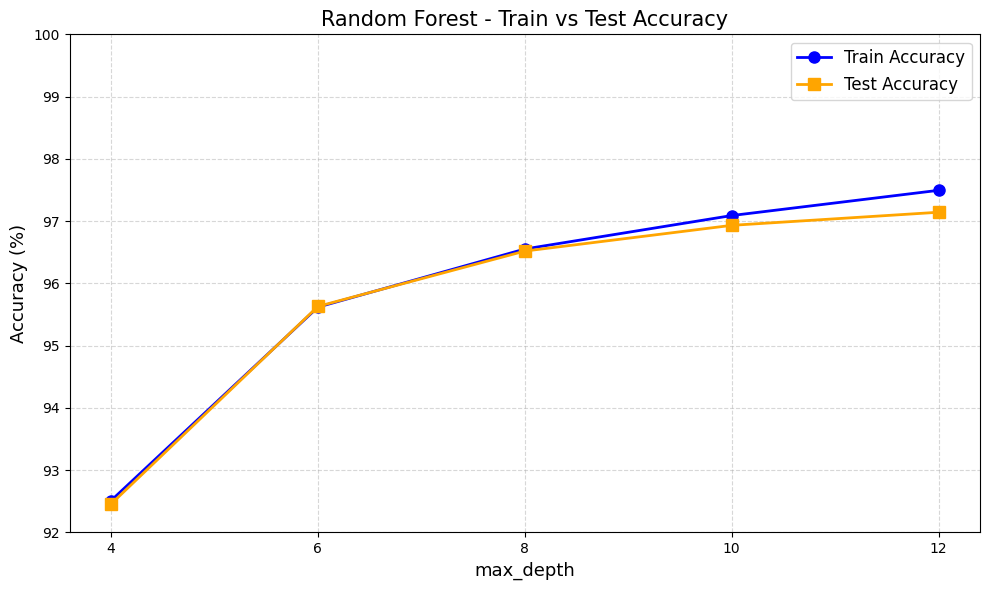

In [35]:
plt.figure(figsize=(10, 6))
plt.plot(max_depth,train_accu_results,color='blue',marker='o',linewidth=2,markersize=8,label='Train Accuracy')
plt.plot(max_depth,test_accu_results,color='orange',marker='s',linewidth=2,markersize=8,label='Test Accuracy')

plt.xlabel('max_depth', fontsize=13)
plt.ylabel('Accuracy (%)', fontsize=13)
plt.title('Random Forest - Train vs Test Accuracy', fontsize=15)
plt.xticks(max_depth)
plt.ylim(92, 100)

plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()


<hr color=white>

# **XGBRegressor**

In [39]:
train_mape_results = []
test_mape_results = []

train_accu_results = []
test_accu_results = []

max_depth = [4 , 6 , 8 , 10 , 12]

for i in max_depth:
    XGBRegressor_model1 = XGBRegressor(
        objective="reg:squarederror",
        n_estimators=800,
        learning_rate=0.03,
        max_depth=i,
        random_state=42,
        n_jobs=-1,
    )

    print(f"[+] Training the model [max_depth={i}] ...")
    t1 = time.time()
    XGBRegressor_model1.fit( X_train, y_train, verbose=False
    )
    t2 = time.time()
    diff = t2-t1
    minute = f"{diff//60 :.0f}".zfill(2)
    second = f"{diff% 60 :.0f}".zfill(2)
    print(f"[+] Training Completed Successfully, Took {minute}:{second}")

    y_pred = XGBRegressor_model1.predict(X_train)
    random_forest_train_mape = mean_absolute_percentage_error(y_train , y_pred)
    train_mape_results.append(random_forest_train_mape)
    
    y_pred = XGBRegressor_model1.predict(X_test)
    random_forest_test_mape = mean_absolute_percentage_error(y_test , y_pred)
    test_mape_results.append(random_forest_test_mape)

    train_accu_results.append((1 - random_forest_train_mape) * 100)
    test_accu_results.append((1 - random_forest_test_mape) * 100)
    print("-"*30)

print(f"{train_mape_results=}")
print(f"{test_mape_results=}")
print(f"{train_accu_results=}")
print(f"{test_accu_results=}")

[+] Training the model [max_depth=4] ...
[+] Training Completed Successfully, Took 03:33
------------------------------
[+] Training the model [max_depth=6] ...
[+] Training Completed Successfully, Took 04:21
------------------------------
[+] Training the model [max_depth=8] ...
[+] Training Completed Successfully, Took 05:38
------------------------------
[+] Training the model [max_depth=10] ...
[+] Training Completed Successfully, Took 09:02
------------------------------
[+] Training the model [max_depth=12] ...
[+] Training Completed Successfully, Took 13:20
------------------------------
train_mape_results=[0.03300019799402911, 0.027346268356816757, 0.020985811173989455, 0.014071861731287718, 0.009202273651174882]
test_mape_results=[0.0335855212786837, 0.030847315262335542, 0.028291783595680856, 0.02667566389587886, 0.026330490709039683]
train_accu_results=[96.6999802005971, 97.26537316431832, 97.90141888260105, 98.59281382687122, 99.07977263488252]
test_accu_results=[96.6414478

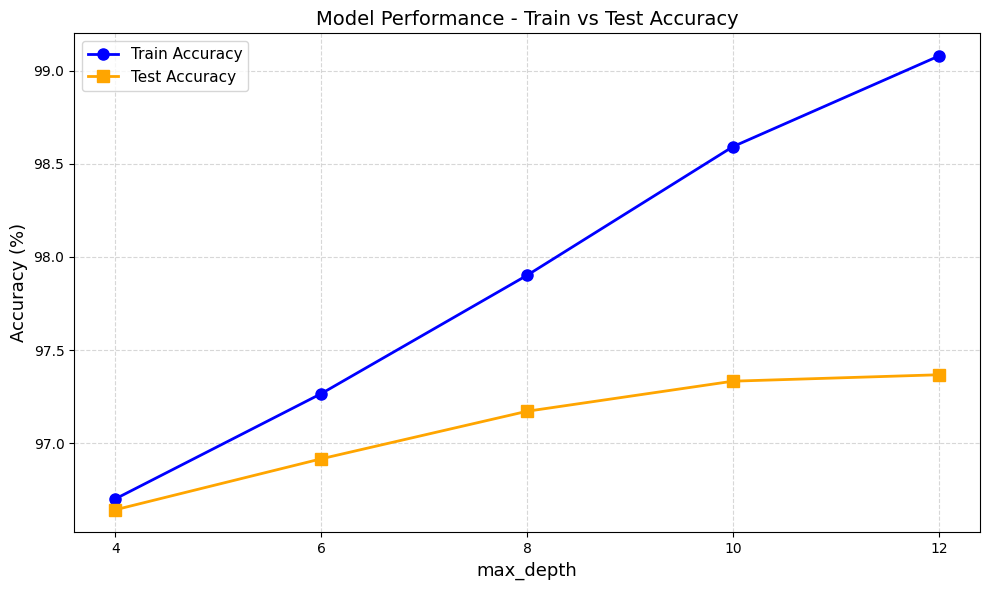

In [40]:
plt.figure(figsize=(10, 6))
plt.plot(max_depth,train_accu_results,color='blue',marker='o',linewidth=2,markersize=8,label='Train Accuracy')
plt.plot(max_depth,test_accu_results,color='orange',marker='s',linewidth=2,markersize=8,label='Test Accuracy')

plt.xlabel('max_depth', fontsize=13)
plt.ylabel('Accuracy (%)', fontsize=13)
plt.title('Model Performance - Train vs Test Accuracy', fontsize=14)
plt.xticks(max_depth)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()


<hr color=white>

### **Models Accuracy Comparison**

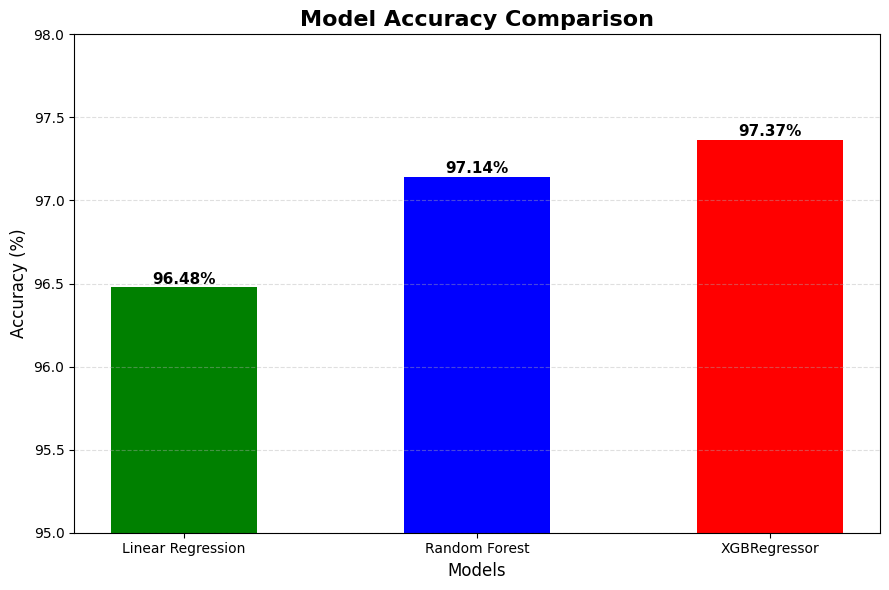

In [42]:
import matplotlib.pyplot as plt

models = ['Linear Regression', 'Random Forest', 'XGBRegressor']
accuracy = [96.47838156304421, 97.14278057816145, 97.36695092909603]

colors = ['green', 'blue', 'red']

# رسم المخطط
plt.figure(figsize=(9, 6))
bars = plt.bar(models, accuracy, color=colors, width=0.5)

# إضافة قيم الدقة فوق الأعمدة
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.02,
        f'{height:.2f}%',
        ha='center',
        fontsize=11,
        fontweight='bold'
    )

# تنسيق الرسم
plt.title('Model Accuracy Comparison', fontsize=16, fontweight='bold')
plt.xlabel('Models', fontsize=12)
plt.ylabel('Accuracy (%)', fontsize=12)
plt.ylim(95, 98)
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

<hr color=white>

### **Actual vs Predicted**

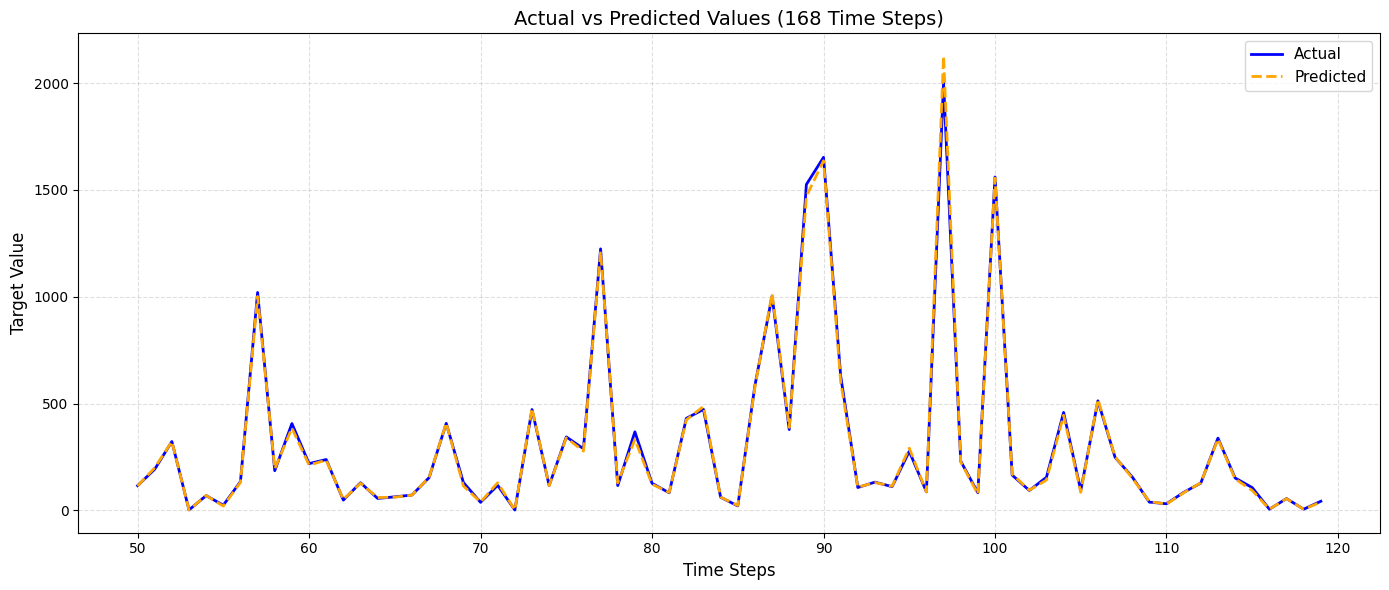

In [43]:
y_pred = XGBRegressor_model1.predict(X_test)

y_pred_original = np.exp(y_pred)
y_test_original = np.exp(np.array(y_test).reshape(-1))

start = 50
end = 120
actual = y_test_original[start:end]
predicted = y_pred_original[start:end]

plt.figure(figsize=(14, 6))

plt.plot( range(start, end),actual, color='blue', linewidth=2,  label='Actual' )
plt.plot(range(start, end),predicted,color='orange',linewidth=2,linestyle='--',label='Predicted')

plt.xlabel('Time Steps', fontsize=12)
plt.ylabel('Target Value', fontsize=12)

plt.title('Actual vs Predicted Values (168 Time Steps)', fontsize=14 )

plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()


## **Save Models**

In [ ]:
import joblib


joblib.dump(Linear_Regression_model, f'{path}/models/Linear_Regression_model.pkl')
joblib.dump(Random_Forest_model, f'{path}/models/Random_Forest_model.pkl')
joblib.dump(XGBRegressor_model1, f'{path}/models/XGBRegressor_model1.pkl')
print("Models saved successfully!")



Model saved successfully!


## **Load Models**

In [ ]:
import joblib


Linear_Regression_model = joblib.load(f'{path}/models/Linear_Regression_model.pkl')
Random_Forest_model = joblib.load(f'{path}/models/Random_Forest_model.pkl')
XGBRegressor_model1 = joblib.load(f'{path}/models/XGBRegressor_model1.pkl')

print("Models loaded successfully!")